In [49]:
#Librerias necesarias
from astropy.io import fits
from astropy.table import Table
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [50]:
#Cambia el orden de bytes de los datos a nativo si es necesario
def _to_native_byteorder(arr: np.ndarray) -> np.ndarray:
    if arr.dtype.byteorder not in ("=", "|"):
        arr = arr.byteswap().view(arr.dtype.newbyteorder("="))
    return arr

#Convierte la tabla FITS a un DataFrame de Pandas, expandiendo las columnas multidimensionales en columnas separadas
def fits_table_to_full_dataframe(astropy_table: Table) -> pd.DataFrame:
    scalar_cols = []
    multidim_cols = []

    for name in astropy_table.colnames:
        col = astropy_table[name]

        if len(col.shape) <= 1:
            scalar_cols.append(name)
        else:
            multidim_cols.append(name)

    for name in astropy_table.colnames:
        data = np.asarray(astropy_table[name])
        if data.dtype.kind in "fiu":  # float, int, unsigned int
            astropy_table[name] = _to_native_byteorder(data)

    df = astropy_table[scalar_cols].to_pandas()

    for col in df.columns:
        if df[col].dtype == object and len(df) > 0 and isinstance(df[col].iloc[0], bytes):
            df[col] = df[col].str.decode("utf-8")

    expanded = {}
    for name in multidim_cols:
        arr = np.asarray(astropy_table[name])  # shape (n_rows, k [, ...])
        arr = arr.reshape(len(arr), -1)        # flatten any extra dims to 2D
        n_sub = arr.shape[1]
        for i in range(n_sub):
            expanded[f"{name}_{i}"] = arr[:, i]

    if expanded:
        df = pd.concat([df, pd.DataFrame(expanded, index=df.index)], axis=1)

    return df, multidim_cols, scalar_cols

#Cuenta el número de valores vacíos en cada columna del DataFrame
def contar_vacios(df):
    conteo = df.isnull().sum()
    for col in df.select_dtypes(include='object').columns:
        vacios_texto = df[col].astype(str).str.strip().eq('').sum()
        conteo[col] = conteo[col] + vacios_texto
    return conteo.sort_values(ascending=False)


In [51]:
hdul = fits.open("gll_psc_v41.fit")
astropy_table = Table.read(hdul[1])  # Index 1 is usually the main catalog table

### Resumen de información general del dataset

In [52]:
df, m_cols, s_cols = fits_table_to_full_dataframe(astropy_table)
rows, cols = df.shape
vacios = contar_vacios(df)

print("="*60)
print(f"Columnas multidimensionales: {len(m_cols)}")
print(f"Columnas unidimensionales: {len(s_cols)}")

print("="*60)
print(f"Columnas con valores nulos/vacios: ")
for col, count in vacios.items():
    if count > 0:
      print(f"{col}: {count}")

print("="*60)
print(f"Número de filas: {rows}")
print(f"Número de columnas: {cols}")
print("="*60)
print(f"Cantidad de columnas (Antes de expandir las multidim): {len(astropy_table.columns)}")
print(f"Cantidad de columnas: {len(df.columns)}")

Columnas multidimensionales: 8
Columnas unidimensionales: 70
Columnas con valores nulos/vacios: 
PriorSigma_Band_6: 7224
PriorSigma_Band_5: 7224
PriorSigma_Band_7: 7224
Unc_PLEC_Exp_Index: 7180
Extended_Source_Name: 7141
ASSOC_GAM3: 7126
ASSOC_GAM2: 7019
ASSOC_TEV: 7019
ASSOC_GAM1: 7005
CLASS2: 6912
ASSOC2: 6820
Unc_Flux_Band_0: 6294
Unc_Flux_Band_14: 5734
ASSOC_FHL: 5695
Unc_Flux_Band_12: 3677
Unc_Flux_Band_2: 3454
PLEC_EPeak: 2418
Unc_PLEC_EPeak: 2418
Unc_Counterpart: 2147
DEC_Counterpart: 2114
ASSOC1: 2114
RA_Counterpart: 2114
CLASS1: 2114
Unc_Flux_Band_10: 1712
Unc_Flux_History_26: 1671
Unc_Flux_History_18: 1626
Unc_Flux_History_28: 1614
Unc_Flux_History_20: 1607
Unc_Flux_History_30: 1606
Unc_Flux_History_24: 1602
Unc_Flux_History_0: 1566
Unc_Flux_History_22: 1565
Unc_Flux_History_8: 1561
Unc_Flux_History_6: 1544
Unc_Flux_History_2: 1536
Unc_Flux_History_16: 1531
Unc_Flux_History_4: 1530
Unc_Flux_History_10: 1499
Unc_Flux_History_12: 1493
Unc_Flux_History_14: 1445
Unc_LP_EPeak: 893

C:\Users\jonha\AppData\Local\Temp\ipykernel_13504\1923078108.py:47: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include='object').columns:


In [53]:
for col in sorted(df.columns):
    print(col)

ASSOC1
ASSOC2
ASSOC_FGL
ASSOC_FHL
ASSOC_GAM1
ASSOC_GAM2
ASSOC_GAM3
ASSOC_PROB_BAY
ASSOC_PROB_LR
ASSOC_TEV
CLASS1
CLASS2
Conf_68_PosAng
Conf_68_SemiMajor
Conf_68_SemiMinor
Conf_95_PosAng
Conf_95_SemiMajor
Conf_95_SemiMinor
DEC_Counterpart
DEJ2000
Energy_Flux100
Extended_Source_Name
Flags
Flux1000
Flux_Band_0
Flux_Band_1
Flux_Band_2
Flux_Band_3
Flux_Band_4
Flux_Band_5
Flux_Band_6
Flux_Band_7
Flux_History_0
Flux_History_1
Flux_History_10
Flux_History_11
Flux_History_12
Flux_History_13
Flux_History_14
Flux_History_15
Flux_History_2
Flux_History_3
Flux_History_4
Flux_History_5
Flux_History_6
Flux_History_7
Flux_History_8
Flux_History_9
Flux_Peak
Frac_Variability
GLAT
GLON
LP_EPeak
LP_Flux_Density
LP_Index
LP_SigCurv
LP_beta
Npred
PLEC_EPeak
PLEC_Exp_Index
PLEC_ExpfactorS
PLEC_Flux_Density
PLEC_IndexS
PLEC_SigCurv
PL_Flux_Density
PL_Index
Peak_Interval
Pivot_Energy
PriorSigma_Band_0
PriorSigma_Band_1
PriorSigma_Band_2
PriorSigma_Band_3
PriorSigma_Band_4
PriorSigma_Band_5
PriorSigma_Band_6
Pr

In [54]:
def drop_columns(df, prefix):
    columns_to_drop = [col for col in df.columns if col.startswith(prefix)]
    df = df.drop(columns=columns_to_drop)
    return df

df_modificado = df.drop(columns=[
    "RAJ2000",
    "DEJ2000",
    "GLON",
    "GLAT",
    "ROI_num",
    "Extended_Source_Name",
    "Flags",
    "PriorSigma_Band_5",
    "PriorSigma_Band_6",
    "PriorSigma_Band_7",
    "Source_Name",
    "CLASS2",#La dropee, pero hay 200 datos catalogados con solo esta clase, se puede retomar
])

df_modificado = drop_columns(df_modificado, "Conf_68")
df_modificado = drop_columns(df_modificado, "Conf_95")
df_modificado = drop_columns(df_modificado, "ASSOC")
df_modificado = drop_columns(df_modificado, "Unc")
df_modificado

,Signif_Avg,Pivot_Energy,Flux1000,Energy_Flux100,SpectrumType,PL_Flux_Density,PL_Index,LP_Flux_Density,LP_Index,LP_beta,...,Sqrt_TS_History_6,Sqrt_TS_History_7,Sqrt_TS_History_8,Sqrt_TS_History_9,Sqrt_TS_History_10,Sqrt_TS_History_11,Sqrt_TS_History_12,Sqrt_TS_History_13,Sqrt_TS_History_14,Sqrt_TS_History_15
0,13.239755,3225.087891,2.344568e-10,2.078138e-12,LogParabola,2.248986e-14,1.890935,2.770070e-14,1.654283,0.186051,...,3.262163,3.333412,0.000000,4.870976,3.400242,1.004901,3.083654,3.978457,5.470551,3.562968
1,10.128918,2473.387207,1.555349e-10,1.738560e-12,PowerLaw,2.568005e-14,2.124405,2.942658e-14,1.999734,0.114887,...,4.007673,3.072232,0.000000,0.138475,0.851327,2.582566,2.180518,3.022064,2.635773,4.323552
2,6.249901,1218.181030,1.665085e-10,2.136813e-12,PowerLaw,1.430262e-13,2.368909,1.766163e-13,2.251119,0.188341,...,2.078092,2.816203,5.069758,0.942609,0.606106,0.000000,3.331759,0.206782,2.644264,0.337780
3,4.890882,7703.233887,6.480765e-11,8.144599e-13,PowerLaw,1.372683e-15,1.779881,1.608383e-15,1.717277,0.110542,...,1.381091,1.185553,0.676677,0.000000,1.800257,0.000000,0.000000,1.040098,2.699368,0.000000
4,24.774321,2242.419922,6.442757e-10,7.156541e-12,PowerLaw,1.303423e-13,2.059213,1.404276e-13,2.015967,0.055393,...,6.157365,6.864655,11.006454,5.270002,5.259351,3.115171,6.220970,3.049019,2.421250,3.803530
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7219,22.441393,2818.198242,4.147472e-10,4.758268e-12,PowerLaw,5.295255e-14,1.919448,5.463048e-14,1.895177,0.019037,...,3.278689,5.690301,5.343624,3.668833,5.831947,6.763502,5.235860,7.540151,6.786489,9.687078
7220,6.051024,2925.482178,1.234013e-10,1.383477e-12,PowerLaw,1.422179e-14,2.137818,1.709104e-14,1.981336,0.170132,...,1.449162,3.947807,1.199068,2.851275,1.833795,1.603811,2.877516,2.527517,0.000000,2.941564
7221,8.878569,583.398804,1.303113e-10,2.602351e-12,PowerLaw,9.713806e-13,2.720781,1.011778e-12,2.714228,0.032970,...,4.374098,5.148923,10.520814,1.221563,0.234969,4.391251,0.414187,0.386400,0.000000,0.144170
7222,11.436264,1397.758545,2.273546e-10,1.613994e-12,LogParabola,1.096676e-13,2.121610,1.343889e-13,1.947950,0.195313,...,2.822704,1.480030,2.695048,1.936572,2.890949,3.162603,3.766587,4.163330,0.997666,1.351216


In [55]:
df_limpio = df_modificado.drop(df[df["CLASS1"].str.strip() == ""].index)
df_limpio["CLASS1"] = df_limpio["CLASS1"].str.lower()
df_limpio["CLASS1"] = df_limpio["CLASS1"].str.strip()

df_limpio["CLASS1"] = df_limpio["CLASS1"].apply(lambda x : x if x in ["bll", "bcu", "fsrq"] else "other")

df_limpio = df_limpio.dropna()
print(df_limpio["CLASS1"].value_counts())
df_limpio


CLASS1
bll      1364
bcu       812
other     709
fsrq      219
Name: count, dtype: int64


,Signif_Avg,Pivot_Energy,Flux1000,Energy_Flux100,SpectrumType,PL_Flux_Density,PL_Index,LP_Flux_Density,LP_Index,LP_beta,...,Sqrt_TS_History_6,Sqrt_TS_History_7,Sqrt_TS_History_8,Sqrt_TS_History_9,Sqrt_TS_History_10,Sqrt_TS_History_11,Sqrt_TS_History_12,Sqrt_TS_History_13,Sqrt_TS_History_14,Sqrt_TS_History_15
0,13.239755,3225.087891,2.344568e-10,2.078138e-12,LogParabola,2.248986e-14,1.890935,2.770070e-14,1.654283,0.186051,...,3.262163,3.333412,0.000000,4.870976,3.400242,1.004901,3.083654,3.978457,5.470551,3.562968
4,24.774321,2242.419922,6.442757e-10,7.156541e-12,PowerLaw,1.303423e-13,2.059213,1.404276e-13,2.015967,0.055393,...,6.157365,6.864655,11.006454,5.270002,5.259351,3.115171,6.220970,3.049019,2.421250,3.803530
6,18.958750,2625.835693,3.020277e-10,3.276111e-12,LogParabola,4.149534e-14,1.787867,4.605722e-14,1.638008,0.084914,...,2.099031,4.086499,8.358863,7.564757,0.438912,1.733235,5.808522,6.915789,0.772094,4.501792
7,5.896947,3310.959717,1.160190e-10,1.291763e-12,PowerLaw,1.062519e-14,2.023382,1.080272e-14,1.974461,0.031902,...,2.048940,2.613832,0.289825,0.233037,1.497857,3.259107,0.005513,0.369537,1.573167,2.160707
10,6.539914,1916.025269,4.841779e-10,4.465203e-12,LogParabola,1.146675e-13,2.562981,1.528474e-13,2.657951,0.234582,...,0.541087,1.025569,1.029004,1.887214,3.150911,2.382132,1.868572,1.294344,1.674093,0.395934
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7215,24.201912,4004.220947,4.217226e-10,5.201231e-12,PowerLaw,2.846089e-14,1.802985,2.930294e-14,1.780870,0.016622,...,4.143924,5.638003,3.239370,6.330638,7.628477,3.208753,6.286846,5.589690,5.361878,5.653288
7217,7.637436,3176.555908,1.334187e-10,1.490603e-12,PowerLaw,1.334886e-14,2.001655,1.677994e-14,1.882736,0.139626,...,1.351113,1.297331,1.627409,1.087298,2.578324,1.157350,3.215744,0.000000,0.000000,2.685766
7218,10.955261,4482.043457,1.725179e-10,1.597517e-12,LogParabola,8.925771e-15,1.773881,1.450835e-14,1.512790,0.358769,...,0.098520,0.000000,0.534284,5.306421,4.840524,1.471421,3.330034,3.738104,5.862391,3.179455
7219,22.441393,2818.198242,4.147472e-10,4.758268e-12,PowerLaw,5.295255e-14,1.919448,5.463048e-14,1.895177,0.019037,...,3.278689,5.690301,5.343624,3.668833,5.831947,6.763502,5.235860,7.540151,6.786489,9.687078


In [56]:
df["SpectrumType"].value_counts()

SpectrumType
PowerLaw            3697
LogParabola         3217
PLSuperExpCutoff     310
Name: count, dtype: int64

In [57]:
df_limpio.describe()

c:\Users\jonha\OneDrive - Universidad Nacional de Colombia\coding\Opt-IA\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4608: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a
c:\Users\jonha\OneDrive - Universidad Nacional de Colombia\coding\Opt-IA\.venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\jonha\OneDrive - Universidad Nacional de Colombia\coding\Opt-IA\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4608: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = b - a
c:\Users\jonha\OneDrive - Universidad Nacional de Colombia\coding\Opt-IA\.venv\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)
c:\Users\jonha\OneDrive - Universidad Nacional de Colombia\coding\Opt-IA\.venv\Lib\site-packages\numpy\lib\_function_base_impl.py:4608

,Signif_Avg,Pivot_Energy,Flux1000,Energy_Flux100,PL_Flux_Density,PL_Index,LP_Flux_Density,LP_Index,LP_beta,LP_SigCurv,...,Sqrt_TS_History_6,Sqrt_TS_History_7,Sqrt_TS_History_8,Sqrt_TS_History_9,Sqrt_TS_History_10,Sqrt_TS_History_11,Sqrt_TS_History_12,Sqrt_TS_History_13,Sqrt_TS_History_14,Sqrt_TS_History_15
count,3104.000000,3104.000000,3.104000e+03,3.104000e+03,3.104000e+03,3104.000000,3.104000e+03,3104.000000,3104.000000,3104.000000,...,3104.000000,3104.000000,3104.000000,3104.000000,3104.000000,3104.000000,3104.000000,3104.000000,3104.000000,3104.000000
mean,21.549341,3374.097412,2.163682e-09,1.730868e-11,4.054656e-11,2.150385,3.387664e-11,2.045734,0.189600,3.900355,...,5.641092,5.725036,5.684724,5.497466,5.536888,5.545693,5.577491,5.668633,5.669907,5.617060
std,40.485302,4852.256348,2.778347e-08,1.906122e-10,2.205292e-09,0.293336,1.817746e-09,0.353020,0.141321,9.077782,...,13.822909,14.478148,15.491969,14.750032,13.723115,13.746247,14.295355,14.235517,14.864172,13.853095
min,4.059583,54.240368,1.330050e-11,3.293429e-13,4.845122e-19,1.114420,6.431720e-17,1.047574,0.001403,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.615235,1450.867462,1.443957e-10,1.597347e-12,1.242025e-14,1.929665,1.467892e-14,1.804056,0.081822,1.330325,...,1.366196,1.467630,1.354428,1.266164,1.299171,1.385407,1.344109,1.349545,1.290519,1.378390
50%,10.644644,2339.851929,2.842054e-10,2.946745e-12,6.952903e-14,2.107291,8.155847e-14,1.990824,0.152762,2.281825,...,2.958960,2.884139,2.816936,2.787173,2.825835,2.773291,2.785448,2.830443,2.726794,2.788096
75%,21.033085,3959.627686,7.582300e-10,7.050838e-12,3.704506e-13,2.368827,4.792607e-13,2.240465,0.265890,3.779059,...,5.463848,5.247296,5.374916,5.208560,5.334818,5.319802,5.227600,5.448801,5.470644,5.264873
max,915.437561,171602.359375,1.328944e-06,9.278081e-09,1.228647e-07,3.557798,1.012725e-07,3.270051,0.984779,263.452515,...,368.594421,379.176147,409.272034,335.068268,343.999176,346.159851,348.724609,345.237579,346.661072,350.596130


In [58]:
df_class = df_limpio[[
    "CLASS1",
    "Variability_Index",
    "Frac_Variability",
    "LP_Index",
    "PL_Index",
    "Pivot_Energy",
    "Flux_Band_0",
    "Flux_Band_1",
    "Flux_Band_2",
    "Flux_Band_3",
    "Flux_Band_4",
    "Flux_Band_5",
    "Flux_Band_6",
    "Flux_Band_7",
    "Flux_History_0",
    "Flux_History_1",
    "Flux_History_2",
    "Flux_History_3",
    "Flux_History_4",
    "Flux_History_5",
    "Flux_History_6",
    "Flux_History_7",
    "Flux_History_8",
    "Flux_History_9",
    "Flux_History_10",
    "Flux_History_11",
    "Flux_History_12",
    "Flux_History_13",
    "Flux_History_14",
    "Flux_History_15",
    "nuFnu_Band_0",
    "nuFnu_Band_1",
    "nuFnu_Band_2",
    "nuFnu_Band_3",
    "nuFnu_Band_4",
    "nuFnu_Band_5",
    "nuFnu_Band_6",
    "nuFnu_Band_7",
    ]]




In [59]:
from sklearn.feature_selection import f_classif

X = df_class.select_dtypes(include=["number"])
y = df_class["CLASS1"]

f_scores, p_values = f_classif(X, y)
resultado = pd.DataFrame({"variable": X.columns, "f_score": f_scores, "p_value": p_values})
print(resultado.sort_values("f_score", ascending=False))

             variable     f_score        p_value
3            PL_Index  646.790682   0.000000e+00
2            LP_Index  478.665433  1.466296e-255
1    Frac_Variability  223.911748  1.759804e-131
0   Variability_Index   32.100674   1.986914e-20
4        Pivot_Energy   21.098484   1.581416e-13
11        Flux_Band_6   20.735905   2.672906e-13
35       nuFnu_Band_6   20.514139   3.684741e-13
29       nuFnu_Band_0   12.646227   3.248533e-08
6         Flux_Band_1   12.555826   3.701742e-08
5         Flux_Band_0   12.447650   4.327835e-08
30       nuFnu_Band_1   12.396005   4.663021e-08
17     Flux_History_4   12.194388   6.239141e-08
24    Flux_History_11   12.090904   7.244707e-08
16     Flux_History_3   12.090423   7.249737e-08
20     Flux_History_7   12.001894   8.238217e-08
23    Flux_History_10   11.993792   8.335152e-08
22     Flux_History_9   11.978101   8.526127e-08
18     Flux_History_5   11.957252   8.786654e-08
19     Flux_History_6   11.925273   9.201800e-08
13     Flux_History_

                   Variability_Index  Frac_Variability  LP_Index  PL_Index  \
Variability_Index           1.000000          0.154734  0.031992  0.021688   
Frac_Variability            0.154734          1.000000  0.093970  0.122072   
LP_Index                    0.031992          0.093970  1.000000  0.939574   
PL_Index                    0.021688          0.122072  0.939574  1.000000   
Pivot_Energy               -0.031531         -0.161081 -0.389335 -0.456567   
Flux_Band_0                 0.276868          0.007956  0.090211  0.076876   
Flux_Band_1                 0.188090         -0.011715  0.078045  0.052060   
Flux_Band_2                 0.097127         -0.024227  0.063282  0.037471   
Flux_Band_3                 0.059423         -0.028868  0.050404  0.026421   
Flux_Band_4                 0.061041         -0.025913  0.036150  0.012262   
Flux_Band_5                 0.143676         -0.003087 -0.023448 -0.061539   
Flux_Band_6                 0.097190          0.005598 -0.133476

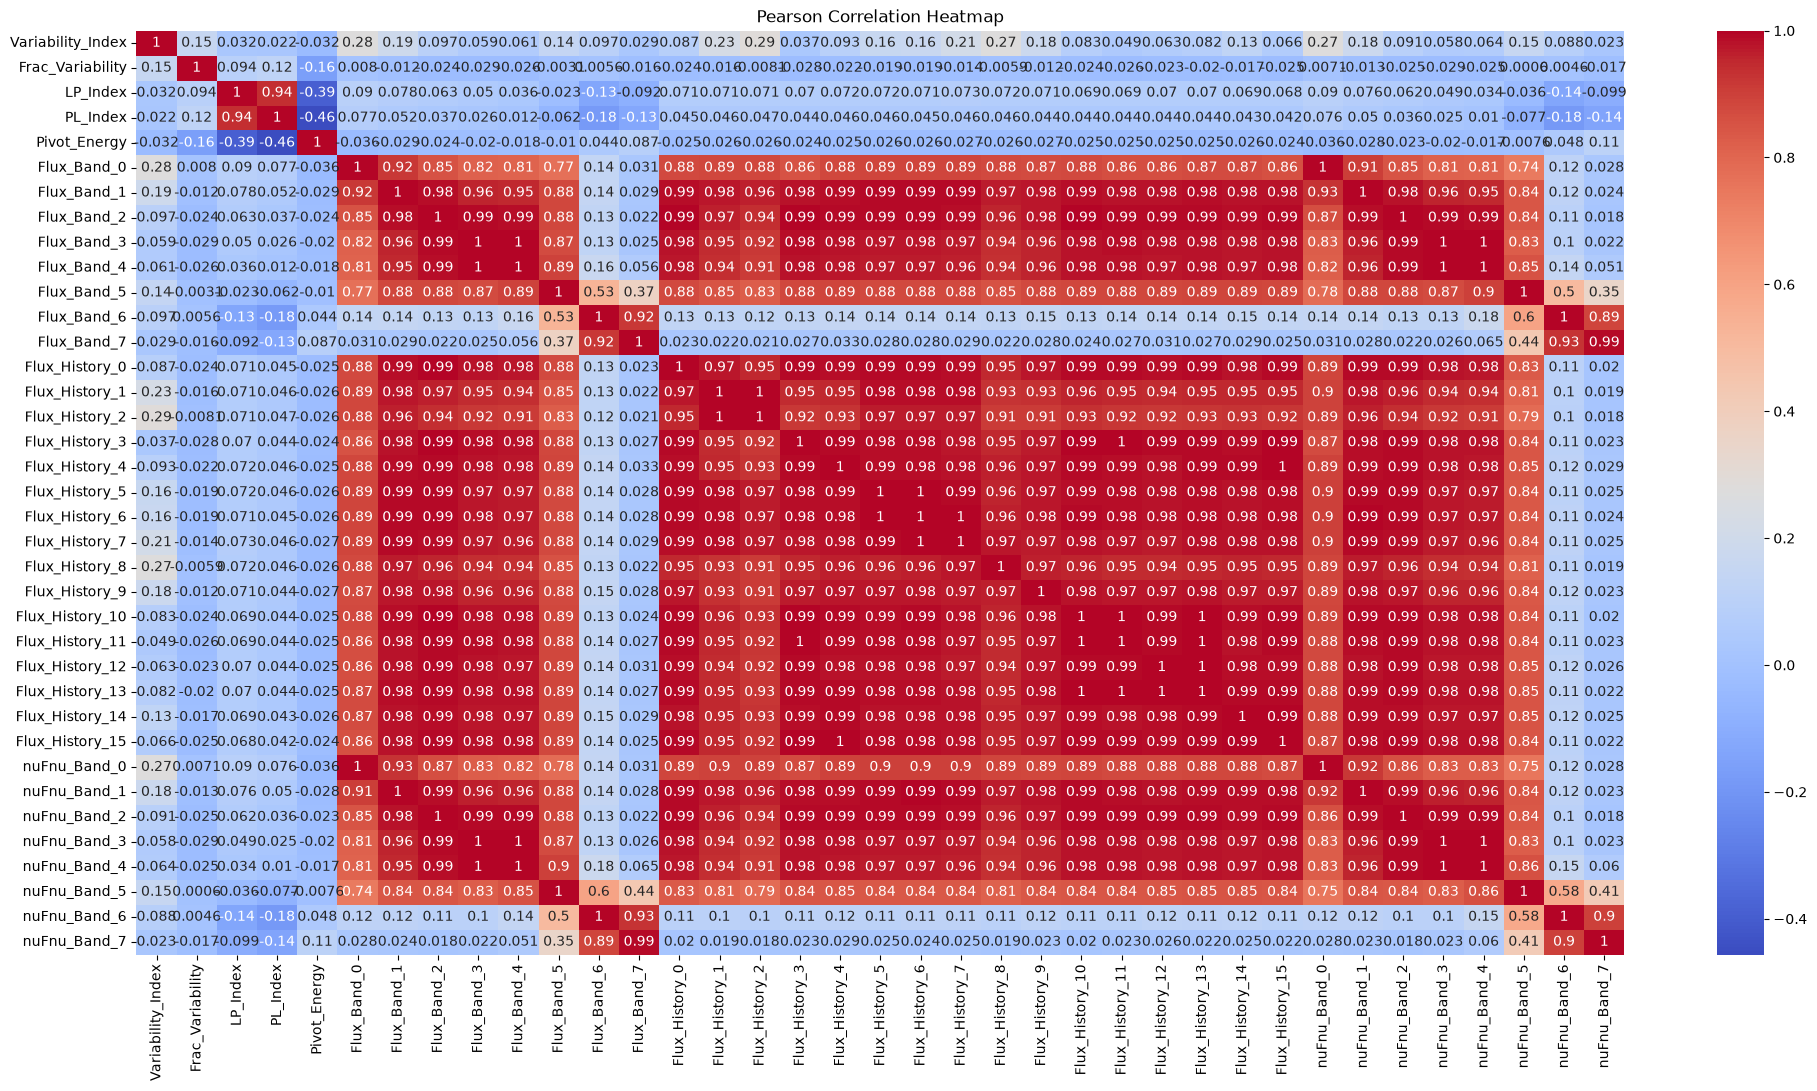

In [60]:
pearson_corr = X.corr(method='pearson')
print(pearson_corr)

plt.figure(figsize=(24, 12))
sns.heatmap(pearson_corr, annot=True, cmap='coolwarm')
plt.title("Pearson Correlation Heatmap")
plt.show()

In [61]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler

In [62]:
#Preparación y escalamiento de datos para el modelo de clasificación
X = df_class.drop("CLASS1", axis=1)
y = df_class["CLASS1"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [63]:
#Entrenar y evaluar modelo
classifier = RandomForestClassifier(n_estimators=200, max_depth=10)
classifier.fit(X_train, y_train)

y_pred = classifier.predict(X_test)

Accuracy: 0.7262479871175523
f1-score: 0.7168723485359035
Confussion Matrix:


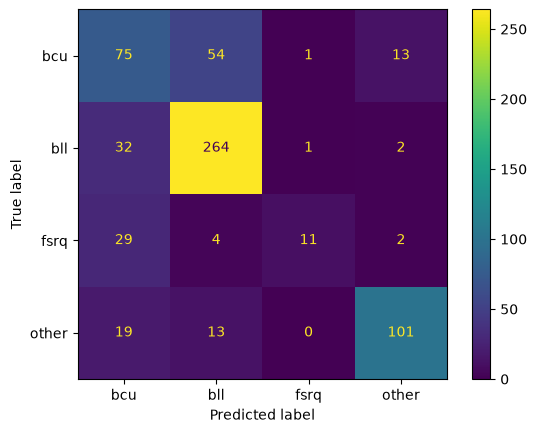

In [64]:
print("Accuracy:", metrics.accuracy_score(y_test, y_pred))
print("f1-score:", metrics.f1_score(y_test, y_pred, average='weighted'))

print("Confussion Matrix:")
cm_mlp = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_mlp, display_labels=classifier.classes_)
disp.plot()

In [65]:
feature_imp = pd.Series(classifier.feature_importances_,index=X.columns).sort_values(ascending=False)
feature_imp

PL_Index             0.090216
LP_Index             0.062314
nuFnu_Band_6         0.057403
Frac_Variability     0.054147
Variability_Index    0.051737
Flux_Band_6          0.050116
Flux_Band_3          0.048493
nuFnu_Band_3         0.045960
nuFnu_Band_5         0.039480
Flux_Band_5          0.030290
Pivot_Energy         0.029786
Flux_Band_4          0.028692
Flux_Band_2          0.027591
nuFnu_Band_4         0.026585
nuFnu_Band_2         0.025036
Flux_History_9       0.018015
Flux_History_1       0.017473
Flux_History_8       0.017131
Flux_History_13      0.016756
Flux_History_4       0.016478
Flux_History_3       0.016474
Flux_History_0       0.016222
nuFnu_Band_7         0.016132
Flux_History_11      0.016026
Flux_History_2       0.015673
Flux_History_10      0.015469
Flux_History_5       0.015329
Flux_History_12      0.014883
Flux_History_7       0.014674
Flux_Band_7          0.014455
nuFnu_Band_0         0.014322
Flux_History_14      0.014196
Flux_History_15      0.013276
Flux_Histo

C:\Users\jonha\AppData\Local\Temp\ipykernel_13504\2149121099.py:12: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


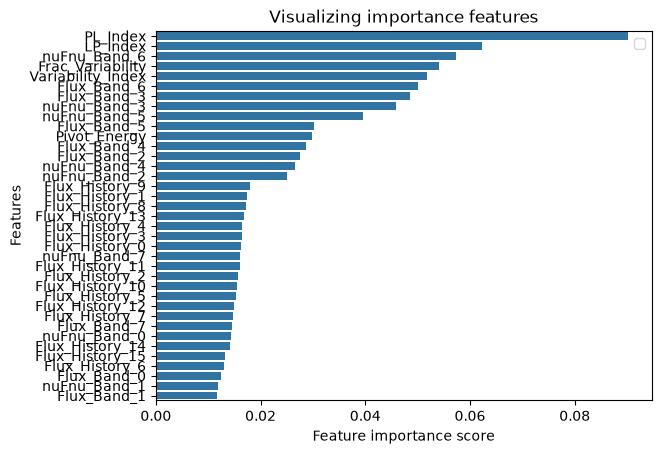

In [66]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

#Este tipo de analisis permite decidir si queremos continuar con todo el conjunto
#de caracteristicas, o seleccionar solo las mas importantes
#Reducir el espacio de representacion permite reducir los costos computacionales
sns.barplot(x=feature_imp, y=feature_imp.index)
plt.xlabel('Feature importance score')
plt.ylabel('Features')
plt.title("Visualizing importance features")
plt.legend()
plt.show()